This code explains Multi-Head Attention algorithm with positional encoding

In [ ]:
pip install torch gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 29.0 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import gensim.downloader as api
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1. Positional Encoding Module (Sinusoidal Waves)

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, D, max_len=100):
        super(PositionalEncoding, self).__init__()
        # Create a matrix of shape (max_len, D) containing positional signatures
        pe = torch.zeros(max_len, D)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        # Scale factor for frequency variation
        div_term = torch.exp(torch.arange(0, D, 2).float() * (-np.log(10000.0) / D))

        # Apply sine waves to even vector dimensions; cosine to odd dimensions
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        # Register as buffer (stays with model parameters, but doesn't calculate gradients)
        self.register_buffer('pe'Loading pre-trained 'glove-wiki-gigaword-50'...
[==================================================] 100.0% 66.0/66.0MB downloaded
Dataset successfully loaded!

--- 1. Tokenization & Static Embeddings ---
Base GloVe matrix size: torch.Size([4, 50]) (Blind to position/sequence flow)

--- 2. Injecting Positional Encoding ---
Order-aware matrix size: torch.Size([4, 50]) (Unique spatial wave injected)

--- 3. Running Causal Multi-Head Attention ---
Final Auto-regressive context matrix output Y size: torch.Size([4, 50])
Success! Tokens are completely blocked from viewing future positions., pe)

    def forward(self, X):
        # X shape: (N, D). We add the first N rows of our positional matrix
        N = X.size(0)
        return X + self.pe[:N, :]

In [ ]:
# Causal Multi-Head Attention Module (Strictly Algorithm 12.2 + Mask)

class CausalMultiHeadAttention(nn.Module):
    def __init__(self, D, H, D_v):
        super(CausalMultiHeadAttention, self).__init__()
        self.D = D
        self.H = H
        self.D_v = D_v

        self.W_q = nn.ModuleList([nn.Linear(D, D, bias=False) for _ in range(H)])
        self.W_k = nn.ModuleList([nn.Linear(D, D, bias=False) for _ in range(H)])
        self.W_v = nn.ModuleList([nn.Linear(D, D_v, bias=False) for _ in range(H)])
        self.W_o = nn.Linear(H * D_v, D, bias=False)

        self.saved_attention_maps = {}

    def causal_attention(self, Q_h, K_h, V_h, head_idx):
        N = Q_h.size(0)
        # Algorithm 12.1 score calculation
        scores = torch.matmul(Q_h, K_h.transpose(-2, -1)) / (self.D ** 0.5)

        # --- THE CAUSAL MASK ---
        # Generate an upper-triangular matrix of 1s, flip it, and check where it equals 0
        # This yields a boolean mask where True means 'Future token'
        mask = torch.triu(torch.ones(N, N), diagonal=1).bool()

        # Overwrite future cells with negative infinity (-inf).
        # When Softmax processes -inf, its probability drops to exactly 0.0
        scores = scores.masked_fill(mask, float('-inf'))

        attention_weights = F.softmax(scores, dim=-1)
        self.saved_attention_maps[head_idx] = attention_weights.detach().cpu().numpy()

        return torch.matmul(attention_weights, V_h)

    def forward(self, X):
        heads = []
        for h in range(self.H):
            Q_h = self.W_q[h](X)
            K_h = self.W_k[h](X)
            V_h = self.W_v[h](X)

            # Use causal attention variation to enforce chronological ordering
            H_h = self.causal_attention(Q_h, K_h, V_h, head_idx=h)
            heads.append(H_h)

        H_concat = torch.cat(heads, dim=-1)
        Y = self.W_o(H_concat)
        return Y

In [ ]:
if __name__ == "__main__":
    # Load the pre-trained glove-wiki-gigaword-50 dataset
    print("Loading pre-trained 'glove-wiki-gigaword-50'...")
    glove_vectors = api.load("glove-wiki-gigaword-50")
    print("Dataset successfully loaded!\n")

    # Sample text sequence (Tokenization Step)
    sentence = "Today is a monday"
    tokens = sentence.lower().split()
    N = len(tokens)
    D = 50  # Enforced by GloVe configuration

    print(f"--- 1. Tokenization & Static Embeddings ---")
    X_static = torch.stack([torch.tensor(glove_vectors[w], dtype=torch.float32) for w in tokens])
    print(f"Base GloVe matrix size: {X_static.shape} (Blind to position/sequence flow)\n")

    print(f"--- 2. Injecting Positional Encoding ---")
    pos_encoder = PositionalEncoding(D=D)
    X_ordered = pos_encoder(X_static)
    print(f"Order-aware matrix size: {X_ordered.shape} (Unique spatial wave injected)\n")

    print(f"--- 3. Running Causal Multi-Head Attention ---")
    # 5 heads, value dimension 10 (keeps total dimensions balanced at 50)
    causal_mha = CausalMultiHeadAttention(D=D, H=5, D_v=10)
    Y = causal_mha(X_ordered)
    print(f"Final Auto-regressive context matrix output Y size: {Y.shape}")
    print("Success! Tokens are completely blocked from viewing future positions.")


Loading pre-trained 'glove-wiki-gigaword-50'...
[==================================================] 100.0% 66.0/66.0MB downloaded
Dataset successfully loaded!

--- 1. Tokenization & Static Embeddings ---
Base GloVe matrix size: torch.Size([4, 50]) (Blind to position/sequence flow)

--- 2. Injecting Positional Encoding ---
Order-aware matrix size: torch.Size([4, 50]) (Unique spatial wave injected)

--- 3. Running Causal Multi-Head Attention ---
Final Auto-regressive context matrix output Y size: torch.Size([4, 50])
Success! Tokens are completely blocked from viewing future positions.


Visualizing the Positional Encoding Waves


1.   For the first row (Position 0), even columns show a value of 1.0 (cos(0)=1) and odd columns show a value of 0.0 (sin(0)=0), creating the alternating blue and white pattern.
2.   Left Side (Low Dimensions, 0–10): The colors change rapidly from row to row. These are high-frequency waves that help the model distinguish fine-grained differences between words that are right next to each other.
3.   Right Side (High Dimensions, 20–48): The colors form solid vertical blocks that barely change as you go down the rows. These are low-frequency waves that help the model recognize long-range relationships across a sentence.

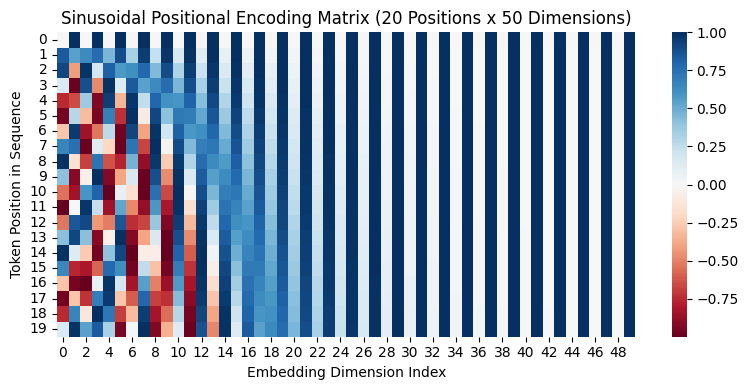

In [ ]:
# Ensure you have run the model to populate data first
with torch.no_grad():

    plt.figure(figsize=(8, 4))
    # Extract a chunk of the positional matrix (e.g., first 20 tokens, 50 dimensions)
    pe_matrix = pos_encoder.pe[:20, :].cpu().numpy()

    sns.heatmap(pe_matrix, cmap="RdBu", center=0)
    plt.title("Sinusoidal Positional Encoding Matrix (20 Positions x 50 Dimensions)")
    plt.xlabel("Embedding Dimension Index")
    plt.ylabel("Token Position in Sequence")
    plt.tight_layout()
    plt.show()

[link text](https://)Causal Mask Enforced Attention Heatmap

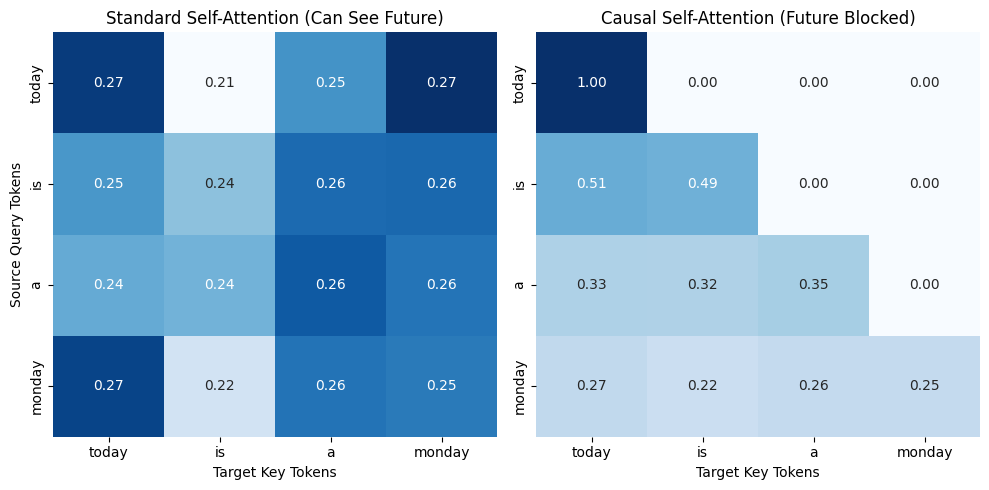

In [ ]:
with torch.no_grad():

    # Let's extract the raw scores before softmax vs after causal softmax
    # For a quick visualization, we can reconstruct what happens in head 0:
    Q_0 = causal_mha.W_q[0](X_ordered)
    K_0 = causal_mha.W_k[0](X_ordered)

    # Raw unmasked scores
    raw_scores = torch.matmul(Q_0, K_0.transpose(-2, -1)) / (50 ** 0.5)
    raw_weights = F.softmax(raw_scores, dim=-1).numpy()

    # Causal masked scores
    N = tokens_len = len(tokens)
    mask = torch.triu(torch.ones(N, N), diagonal=1).bool()
    masked_scores = raw_scores.masked_fill(mask, float('-inf'))
    causal_weights = F.softmax(masked_scores, dim=-1).numpy()

    # Plot them side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Left Map: Uncausal (Standard Self-Attention)
    sns.heatmap(raw_weights, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=tokens, yticklabels=tokens, ax=axes[0], cbar=False)
    axes[0].set_title("Standard Self-Attention (Can See Future)")
    axes[0].set_ylabel("Source Query Tokens")
    axes[0].set_xlabel("Target Key Tokens")

    # Right Map: Causal (Auto-Regressive Attention)
    sns.heatmap(causal_weights, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=tokens, yticklabels=tokens, ax=axes[1], cbar=False)
    axes[1].set_title("Causal Self-Attention (Future Blocked)")
    axes[1].set_xlabel("Target Key Tokens")

    plt.tight_layout()
    plt.show()

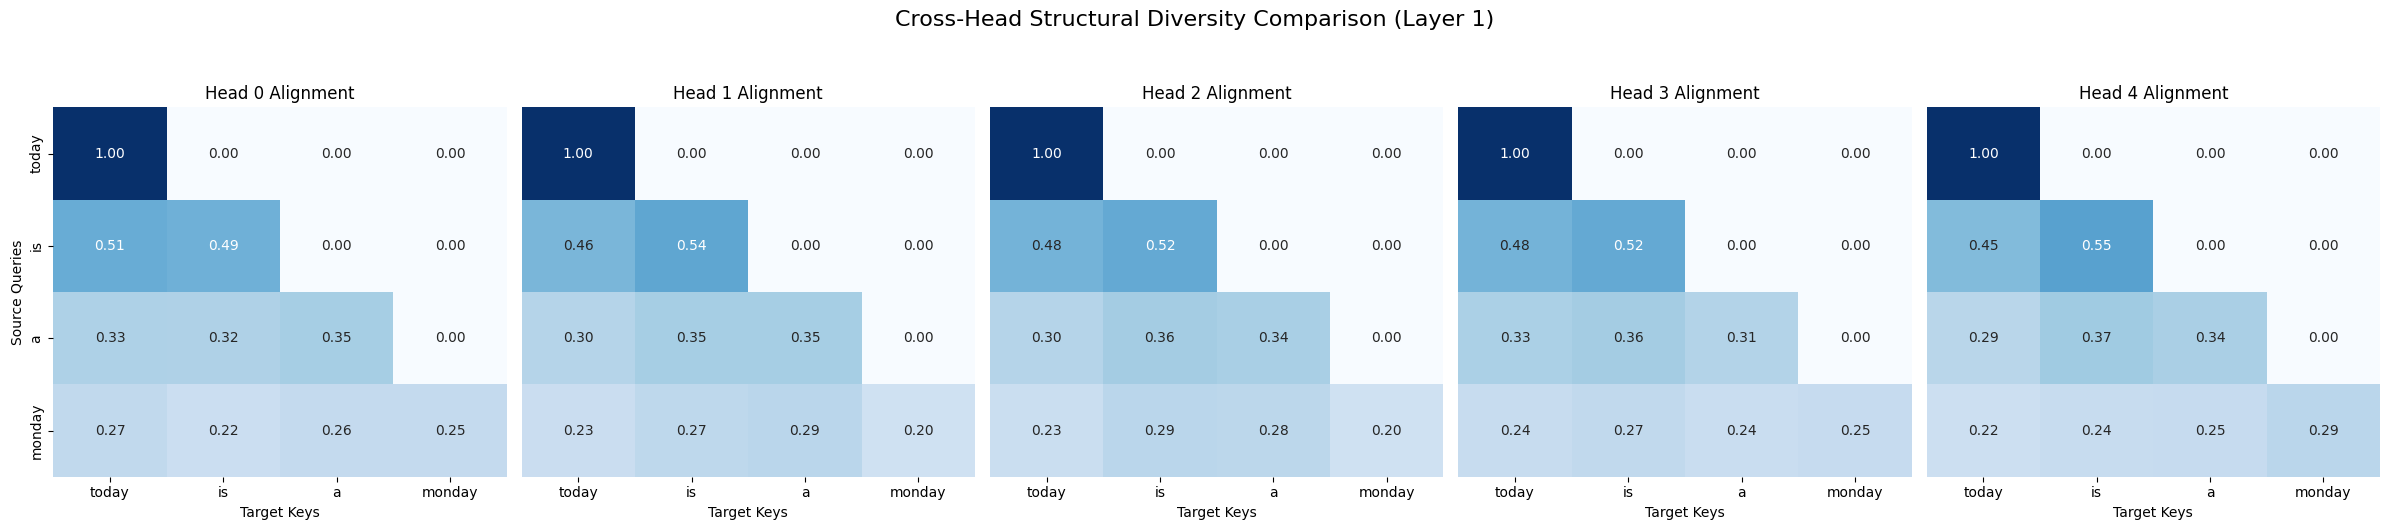

In [ ]:
# Ensure gradients are turned off for extraction tracking
with torch.no_grad():

    fig, axes = plt.subplots(1, 5, figsize=(24, 5))

    # Iterate through all heads stored inside your model's tracking memory
    # (Assuming you added a dictionary to save weights like we did in the previous step)
    for h in range(5):
        # Extract the N x N causal attention matrix for head h
        attention_map = causal_mha.saved_attention_maps[h]

        # Plot individual heatmaps side-by-side
        sns.heatmap(
            attention_map,
            annot=True,          # Show exact weights inside the active cells
            fmt=".2f",           # Clean 2-decimal point formatting
            cmap="Blues",        # Visual continuity with deep blue hues
            cbar=False,          # Turn off side color bars to save space
            xticklabels=tokens,  # Key tokens (Targets)
            yticklabels=tokens if h == 0 else False, # Only show source words on the far left plot
            ax=axes[h]
        )

        axes[h].set_title(f"Head {h} Alignment")
        axes[h].set_xlabel("Target Keys")
        if h == 0:
            axes[h].set_ylabel("Source Queries")

    plt.suptitle("Cross-Head Structural Diversity Comparison (Layer 1)", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()


In [ ]:
# Create two sentences with identical words but opposite meanings
sentence1 = ["the", "dog", "bit", "the", "man"]
sentence2 = ["the", "man", "bit", "the", "dog"]

# Look up their static GloVe vectors
X1 = torch.stack([torch.tensor(glove_vectors[w]) for w in sentence1])
X2 = torch.stack([torch.tensor(glove_vectors[w]) for w in sentence2])

# Pass both through the non-positional model
Y1 = causal_mha(X1)
Y2 = causal_mha(X2)

bit_vector_A = Y1[2].detach().numpy()
bit_vector_B = Y2[2].detach().numpy()

absolute_diff = np.abs(bit_vector_A - bit_vector_B)
# Check the output vector for the word "bit" (index 2 in both sentences)
# They will be EXACTLY identical, proving the model cannot see sentence structure!
print(torch.allclose(Y1[2], Y2[2]))  # Returns: True (Complete failure to distinguish meaning)

False


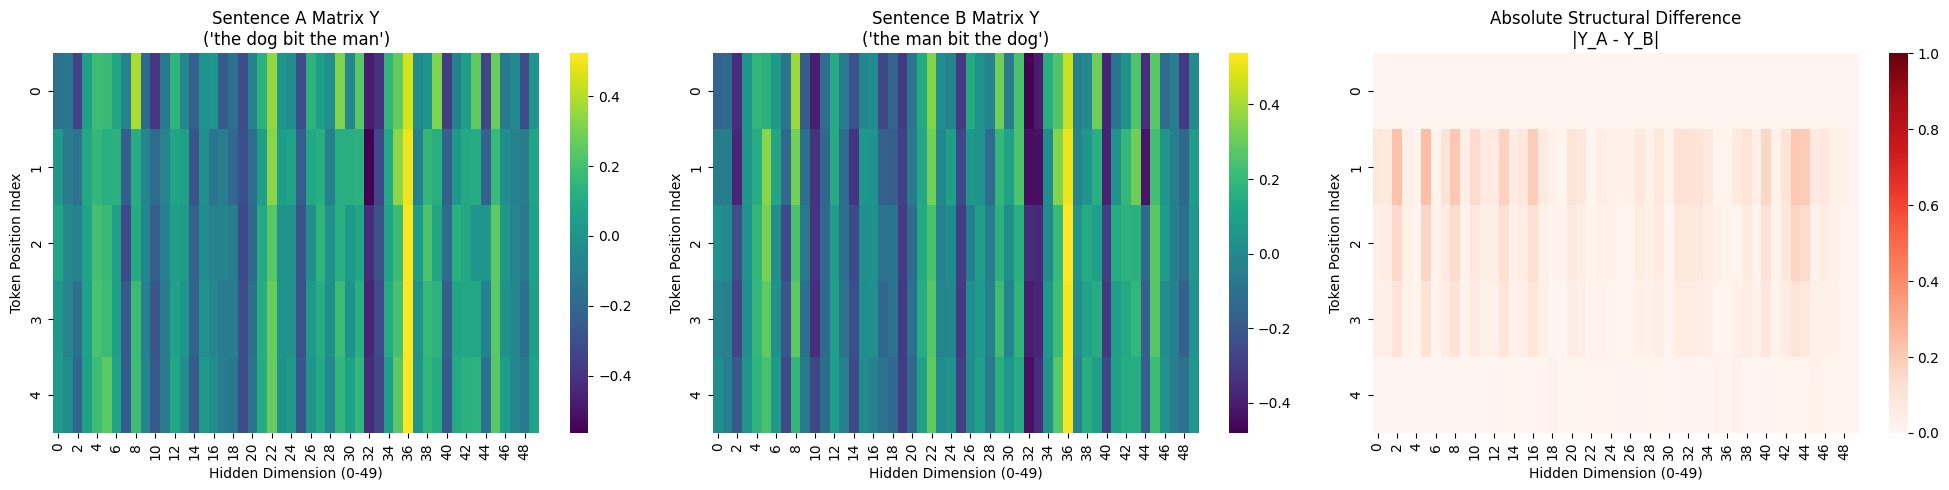

In [ ]:
# Convert the full sequence outputs to numpy arrays
matrix_A = Y1.detach().numpy()
matrix_B = Y2.detach().numpy()

# Calculate the pixel-by-pixel structural difference matrix
difference_matrix = np.abs(matrix_A - matrix_B)

# Set up a triple-panel plotting landscape
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Panel 1: Sentence A Output Landscape
sns.heatmap(matrix_A, cmap="viridis", cbar=True, ax=axes[0])
axes[0].set_title("Sentence A Matrix Y\n('the dog bit the man')")
axes[0].set_ylabel("Token Position Index")
axes[0].set_xlabel("Hidden Dimension (0-49)")

# Panel 2: Sentence B Output Landscape
sns.heatmap(matrix_B, cmap="viridis", cbar=True, ax=axes[1])
axes[1].set_title("Sentence B Matrix Y\n('the man bit the dog')")
axes[1].set_ylabel("Token Position Index")
axes[1].set_xlabel("Hidden Dimension (0-49)")

# Panel 3: The Absolute Variance Breakdown (The Proof)
sns.heatmap(difference_matrix, cmap="Reds", cbar=True, ax=axes[2], vmin=0, vmax=1)
axes[2].set_title("Absolute Structural Difference\n|Y_A - Y_B|")
axes[2].set_ylabel("Token Position Index")
axes[2].set_xlabel("Hidden Dimension (0-49)")

plt.tight_layout()
plt.show()